# CitizenTech — Alerta de chuva forte em São Paulo (IA & Machine Learning)

**Pergunta de ML:** dadas as condições meteorológicas observadas **hoje** na estação INMET A701 (Mirante de Santana, São Paulo), vai haver **chuva forte amanhã** (risco de alagamento)?

- **Tipo de problema:** classificação binária (evento raro → classes desbalanceadas)
- **Modelo:** Random Forest
- **Fonte dos dados:** INMET, dados históricos horários da estação automática A701 (https://portal.inmet.gov.br/dadoshistoricos). Dados reais, sem simulação.
- **Divisão:** temporal (treino = anos antigos, teste = anos mais recentes)
- **Validação cruzada:** `TimeSeriesSplit`, somente dentro do treino


In [1]:
import io, os, re, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, confusion_matrix, precision_recall_curve)
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# ---------------- Configuração ----------------
ESTACAO = "A701"                 # São Paulo - Mirante de Santana (INMET)
ANOS = list(range(2013, 2026))   # período usado
ANO_INICIO_TESTE = 2023          # treino: < 2023 | teste: >= 2023
LIMIAR_CHUVA_MM = 30.0           # chuva forte = precipitação diária >= 30 mm
RAW_DIR = "dados/raw"
os.makedirs(RAW_DIR, exist_ok=True)

## 1. Problema e dados reais

Fonte: **INMET – Banco de Dados Históricos**, arquivos anuais `AAAA.zip` com um CSV por estação (dados horários).
Link: https://portal.inmet.gov.br/dadoshistoricos · Estação: **A701 – São Paulo/Mirante de Santana** · Período: conforme `ANOS` acima.

Limitação assumida: a chuva diária na estação é um **proxy** de risco de alagamento (não há medição direta de alagamento neste conjunto).

In [2]:
def baixar_ano(ano):
    destino = f"{RAW_DIR}/{ano}.zip"
    if not os.path.exists(destino):
        url = f"https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip"
        print("baixando", url)
        r = requests.get(url, timeout=300)
        r.raise_for_status()
        open(destino, "wb").write(r.content)
    return destino

def ler_estacao(zip_path, estacao):
    with zipfile.ZipFile(zip_path) as z:
        nomes = [n for n in z.namelist() if f"_{estacao}_" in n.upper()]
        if not nomes:
            raise FileNotFoundError(f"{estacao} não encontrada em {zip_path}")
        bruto = z.read(nomes[0])
    df = pd.read_csv(io.BytesIO(bruto), sep=";", skiprows=8, encoding="latin-1",
                     decimal=",", na_values=["-9999", "-9999,0"], index_col=False)
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    return df

def achar(df, *palavras):
    for c in df.columns:
        cu = c.upper()
        if all(p in cu for p in palavras):
            return c
    return None

def padronizar(df):
    col_data, col_hora = df.columns[0], df.columns[1]
    hora = df[col_hora].astype(str).str.extract(r"(\d{2}):?(\d{2})")
    ts = pd.to_datetime(df[col_data].astype(str).str.replace("/", "-") + " " + hora[0] + ":" + hora[1],
                        errors="coerce")
    ts = ts.dt.tz_localize("UTC").dt.tz_convert("America/Sao_Paulo").dt.tz_localize(None)
    mapa = {
        "chuva": achar(df, "PRECIPITA"),
        "pressao": achar(df, "PRESS", "ESTA"),
        "temp": achar(df, "TEMPERATURA DO AR"),
        "umid": achar(df, "UMIDADE RELATIVA DO AR"),
        "vento": achar(df, "VENTO, VELOCIDADE"),
        "radiacao": achar(df, "RADIACAO"),
    }
    out = pd.DataFrame({"ts": ts})
    for k, c in mapa.items():
        out[k] = pd.to_numeric(df[c], errors="coerce") if c else np.nan
    return out.dropna(subset=["ts"])

horario = pd.concat([padronizar(ler_estacao(baixar_ano(a), ESTACAO)) for a in ANOS], ignore_index=True)
horario = horario.sort_values("ts").drop_duplicates("ts")
print(horario.shape, horario.ts.min(), "->", horario.ts.max())
horario.head()

baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2013.zip
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2014.zip
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2015.zip
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2016.zip
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2017.zip
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2018.zip
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2019.zip
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2020.zip
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2021.zip
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2022.zip
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2023.zip
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2024.zip
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2025.zip
(113945, 7) 2012-12-31 22:00:00 -> 2025-12-31 20:00:00


,ts,chuva,pressao,temp,umid,vento,radiacao
0,2012-12-31 22:00:00,0.0,925.7,24.8,71.0,2.4,NaN
1,2012-12-31 23:00:00,0.0,925.9,24.2,70.0,0.3,NaN
2,2013-01-01 00:00:00,0.0,924.6,23.4,66.0,2.2,NaN
3,2013-01-01 01:00:00,0.0,924.4,22.1,74.0,2.4,NaN
4,2013-01-01 02:00:00,0.0,923.7,22.5,73.0,1.1,NaN


## 2. Preparação dos dados (limpeza, atributos, alvo e divisão treino/teste)

- Hora UTC convertida para horário de Brasília.
- Agregação **diária**: chuva total e máxima horária, temperatura (máx/mín/média), umidade, pressão (e variação), vento e radiação.
- Atributos de memória: chuva e pressão dos 1–2 dias anteriores, mais sazonalidade (mês em seno/cosseno).
- **Alvo:** `chuva_forte_amanha = 1` se a chuva total do dia seguinte ≥ `LIMIAR_CHUVA_MM`.
- Dias sem observação suficiente (< 20 horas válidas) são descartados.

In [3]:
h = horario.copy()
h["data"] = h.ts.dt.floor("D")
g = h.groupby("data")
dia = pd.DataFrame({
    "horas_validas": g.temp.count(),
    "chuva_total": g.chuva.sum(min_count=1),
    "chuva_max_hora": g.chuva.max(),
    "temp_max": g.temp.max(), "temp_min": g.temp.min(), "temp_media": g.temp.mean(),
    "umid_media": g.umid.mean(), "umid_max": g.umid.max(),
    "pressao_media": g.pressao.mean(),
    "vento_medio": g.vento.mean(),
    "radiacao_max": g.radiacao.max(),
})
dia = dia[dia.horas_validas >= 20].asfreq("D")        # dias faltantes viram NaN
dia["var_pressao"] = dia.pressao_media.diff()
for lag in (1, 2):
    dia[f"chuva_total_lag{lag}"] = dia.chuva_total.shift(lag)
    dia[f"pressao_lag{lag}"] = dia.pressao_media.shift(lag)
dia["mes_sin"] = np.sin(2*np.pi*dia.index.month/12)
dia["mes_cos"] = np.cos(2*np.pi*dia.index.month/12)
dia["chuva_forte_amanha"] = (dia.chuva_total.shift(-1) >= LIMIAR_CHUVA_MM).astype(float)
dia.loc[dia.chuva_total.shift(-1).isna(), "chuva_forte_amanha"] = np.nan

ATRIBUTOS = [c for c in dia.columns if c not in ("horas_validas", "chuva_forte_amanha")]
dados = dia.dropna(subset=["chuva_forte_amanha"]).copy()
dados[ATRIBUTOS] = dados[ATRIBUTOS].fillna(dados[ATRIBUTOS].median())  # mediana (calculada em todo o período; efeito mínimo)
dados.to_csv("dados/inmet_a701_diario_processado.csv")

treino = dados[dados.index.year < ANO_INICIO_TESTE]
teste = dados[dados.index.year >= ANO_INICIO_TESTE]
X_tr, y_tr = treino[ATRIBUTOS], treino.chuva_forte_amanha.astype(int)
X_te, y_te = teste[ATRIBUTOS], teste.chuva_forte_amanha.astype(int)
print(f"Dias úteis: {len(dados)} | treino: {len(treino)} | teste: {len(teste)}")
print(f"Eventos de chuva forte (>= {LIMIAR_CHUVA_MM} mm): treino {y_tr.sum()} ({y_tr.mean():.1%}) | teste {y_te.sum()} ({y_te.mean():.1%})")

Dias úteis: 4695 | treino: 3633 | teste: 1062
Eventos de chuva forte (>= 30.0 mm): treino 130 (3.6%) | teste 47 (4.4%)


**Observação:** a imputação por mediana foi aplicada ao conjunto todo por simplicidade; como só preenche poucos valores faltantes, o impacto é mínimo, mas vale citar como limitação no relatório.

## 3. Escolha justificada do modelo

Usamos **Random Forest** porque: (i) lida bem com dados tabulares e relações não lineares entre pressão, umidade e chuva; (ii) é robusto a atributos em escalas diferentes (sem normalização); (iii) aceita `class_weight="balanced"` para o evento raro; (iv) fornece importância dos atributos, útil para explicar o alerta ao cidadão.

## 4. Treino com diferentes hiperparâmetros

Busca aleatória com **15 combinações** de **3 hiperparâmetros** (`n_estimators`, `max_depth`, `min_samples_leaf`), validação cruzada `TimeSeriesSplit(5)` **apenas no treino** e métrica **PR-AUC (average precision)**, adequada a evento raro.

In [4]:
espaco = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 5, 8, 12, None],
    "min_samples_leaf": [1, 3, 5, 10, 20],
}
busca = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=espaco, n_iter=15,
    cv=TimeSeriesSplit(n_splits=5), scoring="average_precision",
    random_state=RANDOM_STATE, return_train_score=True, n_jobs=-1, refit=True)
busca.fit(X_tr, y_tr)

res = pd.DataFrame(busca.cv_results_)
cols = ["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
        "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]
res = res[cols].sort_values("rank_test_score")
res.columns = ["n_estimators", "max_depth", "min_samples_leaf", "PR-AUC treino (CV)", "PR-AUC validação (CV)", "desvio", "ranking"]
print("Melhores hiperparâmetros:", busca.best_params_)
res.round(3)

Melhores hiperparâmetros: {'n_estimators': 300, 'min_samples_leaf': 20, 'max_depth': 3}


,n_estimators,max_depth,min_samples_leaf,PR-AUC treino (CV),PR-AUC validação (CV),desvio,ranking
10,300,3,20,0.335,0.116,0.030,1
8,300,3,5,0.377,0.106,0.021,2
5,500,5,20,0.513,0.104,0.023,3
9,100,3,1,0.390,0.101,0.018,4
12,200,12,10,0.948,0.099,0.026,5
1,200,8,10,0.880,0.098,0.026,6
13,200,5,10,0.621,0.098,0.022,7
14,300,None,5,1.000,0.095,0.020,8
11,300,5,5,0.651,0.095,0.020,9
3,200,8,3,0.948,0.092,0.021,10


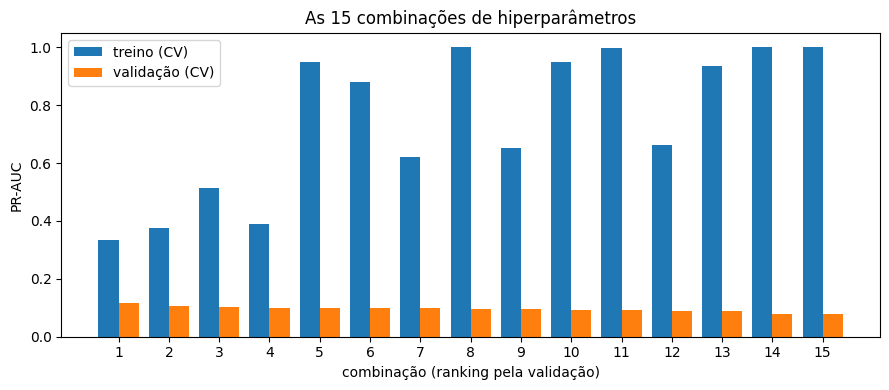

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
r = res.sort_values("ranking")
x = np.arange(len(r))
ax.bar(x - 0.2, r["PR-AUC treino (CV)"], 0.4, label="treino (CV)")
ax.bar(x + 0.2, r["PR-AUC validação (CV)"], 0.4, label="validação (CV)")
ax.set_xticks(x); ax.set_xticklabels(r["ranking"].astype(int))
ax.set_xlabel("combinação (ranking pela validação)"); ax.set_ylabel("PR-AUC")
ax.set_title("As 15 combinações de hiperparâmetros"); ax.legend(); plt.tight_layout(); plt.show()

## 5. Resultados em treino e teste

In [6]:
modelo = busca.best_estimator_
def metricas(X, y):
    p = modelo.predict_proba(X)[:, 1]; yhat = (p >= 0.5).astype(int)
    return {"Precisão": precision_score(y, yhat, zero_division=0), "Recall": recall_score(y, yhat),
            "F1": f1_score(y, yhat), "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p)}, p, yhat

m_tr, p_tr, yh_tr = metricas(X_tr, y_tr)
m_te, p_te, yh_te = metricas(X_te, y_te)
tabela = pd.DataFrame({"Treino": m_tr, "Teste": m_te}).round(3)
print("Linha de base (prevalência no teste):", round(y_te.mean(), 3))
tabela

Linha de base (prevalência no teste): 0.044


,Treino,Teste
Precisão,0.100,0.105
Recall,0.846,0.787
F1,0.179,0.185
PR-AUC,0.185,0.126
ROC-AUC,0.847,0.792


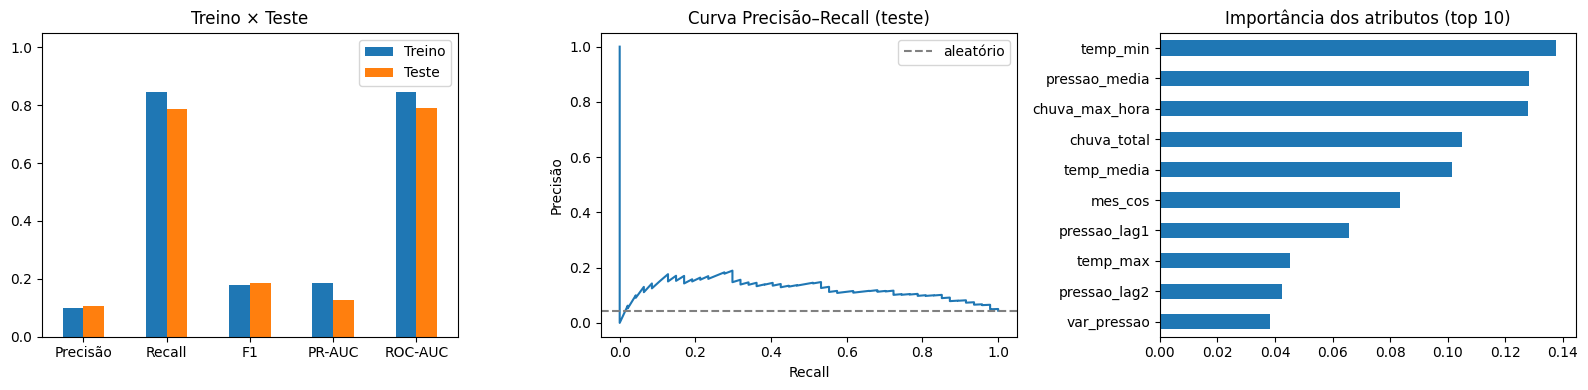

Matriz de confusão (teste) [linhas = real, colunas = previsto]:
 [[700 315]
 [ 10  37]]
Alarmes emitidos: 352 | acertos: 37 | alarmes falsos: 315 | eventos perdidos: 10


In [7]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
tabela.plot.bar(ax=axs[0], rot=0); axs[0].set_title("Treino × Teste"); axs[0].set_ylim(0, 1.05)
pr, rc, _ = precision_recall_curve(y_te, p_te)
axs[1].plot(rc, pr); axs[1].axhline(y_te.mean(), ls="--", c="gray", label="aleatório")
axs[1].set_xlabel("Recall"); axs[1].set_ylabel("Precisão"); axs[1].set_title("Curva Precisão–Recall (teste)"); axs[1].legend()
imp = pd.Series(modelo.feature_importances_, index=ATRIBUTOS).sort_values().tail(10)
imp.plot.barh(ax=axs[2]); axs[2].set_title("Importância dos atributos (top 10)")
plt.tight_layout(); plt.show()

cm = confusion_matrix(y_te, yh_te)
print("Matriz de confusão (teste) [linhas = real, colunas = previsto]:\n", cm)
print(f"Alarmes emitidos: {cm[:,1].sum()} | acertos: {cm[1,1]} | alarmes falsos: {cm[0,1]} | eventos perdidos: {cm[1,0]}")

## 6. Discussão: overfitting

Compare, na tabela acima, as métricas de **treino** e **teste**: uma queda grande de treino para teste (principalmente em PR-AUC e F1) indica overfitting. Compare também a PR-AUC de treino e de validação na busca de hiperparâmetros. Interprete em `RELATORIO_ML.md` com os números desta execução.

## 7. O que o resultado significa para o cidadão

Para o alarme da CitizenTech, o trade-off é: **recall alto** significa poucas enchentes sem aviso; **precisão alta** significa poucos alarmes falsos (que fazem a população parar de confiar no aviso). Os números do cenário de teste acima dizem quantos alertas o sistema teria disparado, quantos foram reais e quantos eventos passaram sem aviso. Os pontos de segurança da CitizenTech são fictícios no protótipo, mas o gatilho do alarme usa apenas dados reais.